# Pneumonia Detection from Chest X-rays Using a CNN (corrected version)
Muhammad Talha Tahir 

FA23-BBD-107

This notebook trains and evaluates a convolutional neural network (CNN) on the real Kaggle
[Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) dataset.
It runs in **VS Code (Jupyter) on Windows**, Linux or macOS.

Expected folder structure (point `DATA_DIR` at the folder that directly contains `train`, `val` and `test`):

```text
chest_xray/
  train/  NORMAL/  PNEUMONIA/
  val/    NORMAL/  PNEUMONIA/
  test/   NORMAL/  PNEUMONIA/
```

## What was fixed compared with the original notebook

| # | Problem in the original | Fix in this version |
|---|---|---|
| 1 | The Kaggle `val` folder has only **16 images**, so early stopping / LR scheduling were driven by a very noisy signal. | `train` + `val` are merged and re-split into **80 % train / 20 % validation**, stratified by class. |
| 2 | Several X-rays come from the same patient. A random split would leak patients between train and validation. | The split is **grouped by patient ID** (parsed from the file names), so no patient appears in both sets. |
| 3 | The data is imbalanced (~74 % PNEUMONIA). The model was trained with no correction. | **Class weights** are used during training. |
| 4 | `AveragePooling2D(2)` right after `Rescaling` silently reduced the 128 px input to 64 px, throwing away fine detail. | Removed. The CNN now sees the full 128 × 128 image. Convolution blocks also use **BatchNormalization**. |
| 5 | `RandomFlip("horizontal")` mirrors the heart to the wrong side, which is not a realistic chest X-ray. | Horizontal flip removed. Small rotation / zoom / shift / contrast augmentation is kept. |
| 6 | Early stopping used `val_loss` only; accuracy alone is misleading for imbalanced medical data. | AUC, precision and recall are tracked; checkpointing / early stopping use **validation AUC**. |
| 7 | Single-image prediction resized with PIL (bicubic) while training used TensorFlow (bilinear), a train/inference mismatch. | One shared preprocessing function is used for training, testing, single-image prediction and Gradio. |
| 8 | `print(f"\\n{split} ...")` and the Gradio note used `\\n` inside a normal string, so a literal `\n` was printed. | Fixed. |
| 9 | Threshold fixed at 0.5 with no justification. | The decision threshold is **tuned on the validation set only**, and the test set is reported at both 0.5 and the tuned threshold. |
| 10 | Only one small model, so no baseline to compare against. | Added an optional **MobileNetV2 transfer-learning** model; the best model is selected by **validation** AUC (never by test results). |
| 11 | Conclusion had blank placeholders. | A results table is generated automatically from your actual run. |

> **Medical disclaimer:** this is an educational prototype. It is not clinically validated and must not be used for diagnosis or treatment decisions.

## 1. Install required packages

Run this cell once. If TensorFlow fails to install, check that your Python version is supported by the TensorFlow release (Python 3.10 – 3.12 is a safe choice).

In [1]:
# %pip install -U tensorflow numpy pandas matplotlib scikit-learn pillow gradio

## 2. Imports, configuration and paths

Set `DATA_DIR` to your extracted dataset folder. Use a raw string (`r"..."`) for Windows paths. If you extracted the zip and ended up with `chest_xray/chest_xray/`, the code below detects the nested folder automatically.

In [4]:
import os, re, json, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)
from PIL import Image

warnings.filterwarnings("ignore")

# ----------------------------- configuration -----------------------------
SEED = 1
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = int(os.environ.get("EPOCHS", 30))          # upper limit; early stopping decides
RUN_TRANSFER_LEARNING = True                         # set False for a quick CNN-only run
TL_WEIGHTS = None if os.environ.get("TL_WEIGHTS") == "none" else "imagenet"

# CHANGE THIS to your extracted Kaggle dataset folder:
DATA_DIR = pathlib.Path(os.environ.get("CHEST_XRAY_DIR", r"D:\Desktop\DL laib mid\chest_xray"))
# -------------------------------------------------------------------------

# Handle the common nested-folder extraction (chest_xray/chest_xray/train ...)
if not (DATA_DIR / "train").exists() and (DATA_DIR / "chest_xray" / "train").exists():
    DATA_DIR = DATA_DIR / "chest_xray"

OUTPUT_DIR = pathlib.Path("cnn_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]               # NORMAL = 0, PNEUMONIA = 1
IMG_EXTS = {".jpg", ".jpeg", ".png"}

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Dataset folder:", DATA_DIR)
print("Dataset folder exists:", DATA_DIR.exists())

TensorFlow: 2.21.0
GPU devices: []
Dataset folder: D:\Desktop\DL laib mid\chest_xray
Dataset folder exists: True


## 3. Verify the dataset structure

This should list `train`, `val` and `test`, each with `NORMAL` and `PNEUMONIA`.

In [5]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        "Update DATA_DIR in the previous cell to the actual extracted chest_xray folder."
    )

print("Top-level contents:", os.listdir(DATA_DIR))

for split in ["train", "val", "test"]:
    split_path = DATA_DIR / split
    print(f"\n{split} exists:", split_path.exists())
    for cls in CLASS_NAMES:
        cls_path = split_path / cls
        if not cls_path.exists():
            raise FileNotFoundError(f"Missing class folder: {cls_path}")
        n = sum(1 for p in cls_path.iterdir() if p.suffix.lower() in IMG_EXTS)
        print(f"  {cls:<10} {n:>5} images")

Top-level contents: ['chest_xray', 'test', 'train', 'val', '__MACOSX']

train exists: True
  NORMAL      1341 images
  PNEUMONIA   3875 images

val exists: True
  NORMAL         8 images
  PNEUMONIA      8 images

test exists: True
  NORMAL       234 images
  PNEUMONIA    390 images


## 4. Build the datasets

* `train` + `val` from Kaggle are merged, then split 80/20 into training and validation, **stratified by class and grouped by patient** (patient IDs are parsed from the file names such as `person12_bacteria_45.jpeg` or `IM-0115-0001.jpeg`).
* The official `test` folder is kept completely untouched until the final evaluation.
* One `prepare_image` function (grayscale → 128 × 128, bilinear) is used everywhere.

In [6]:
def list_images(split):
    paths, labels = [], []
    for label, cls in enumerate(CLASS_NAMES):
        for p in sorted((DATA_DIR / split / cls).iterdir()):
            if p.suffix.lower() in IMG_EXTS:
                paths.append(str(p)); labels.append(label)
    return np.array(paths), np.array(labels, dtype=np.int32)

def patient_id(path, label):
    """Best-effort patient ID from the Kaggle file names (used to avoid patient leakage)."""
    name = pathlib.Path(path).stem
    m = re.search(r"(person\d+)", name, re.I) or re.search(r"(IM-\d+)", name, re.I)
    return f"{label}_{(m.group(1) if m else name).lower()}"

# ---- merge train + val, then do a patient-grouped, class-stratified split ----
tr_paths, tr_labels = list_images("train")
va_paths, va_labels = list_images("val")
pool_paths  = np.concatenate([tr_paths, va_paths])
pool_labels = np.concatenate([tr_labels, va_labels])
groups = np.array([patient_id(p, l) for p, l in zip(pool_paths, pool_labels)])

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(pool_paths, pool_labels, groups))

X_train, y_train = pool_paths[train_idx], pool_labels[train_idx]
X_val,   y_val   = pool_paths[val_idx],   pool_labels[val_idx]
X_test,  y_test  = list_images("test")

assert not set(groups[train_idx]) & set(groups[val_idx]), "Patient leakage between train and validation!"

summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "NORMAL":    [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "PNEUMONIA": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
})
summary["total"] = summary["NORMAL"] + summary["PNEUMONIA"]
summary["% pneumonia"] = (100 * summary["PNEUMONIA"] / summary["total"]).round(1)
print(summary.to_string(index=False))
print("\nUnique patients (train / val):", len(set(groups[train_idx])), "/", len(set(groups[val_idx])))

# ---- shared preprocessing ----
def prepare_image(img):
    """img: HxWxC or HxW array/tensor (0-255). Returns float32 (IMG_SIZE, IMG_SIZE, 1) in 0-255 range."""
    img = tf.convert_to_tensor(img)
    if img.shape.rank == 2:
        img = img[..., None]
    img = tf.cast(img, tf.float32)
    if img.shape[-1] == 3:
        img = tf.image.rgb_to_grayscale(img)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bilinear")

def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=1, expand_animations=False)
    img.set_shape([None, None, 1])
    return prepare_image(img), tf.reshape(tf.cast(label, tf.float32), [1])

AUTOTUNE = tf.data.AUTOTUNE

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, training=True)
val_ds   = make_ds(X_val,   y_val)
test_ds  = make_ds(X_test,  y_test)     # not shuffled, so order matches y_test

     split  NORMAL  PNEUMONIA  total  % pneumonia
     train    1079       3106   4185         74.2
validation     270        777   1047         74.2
      test     234        390    624         62.5

Unique patients (train / val): 2119 / 531


### Display sample training images

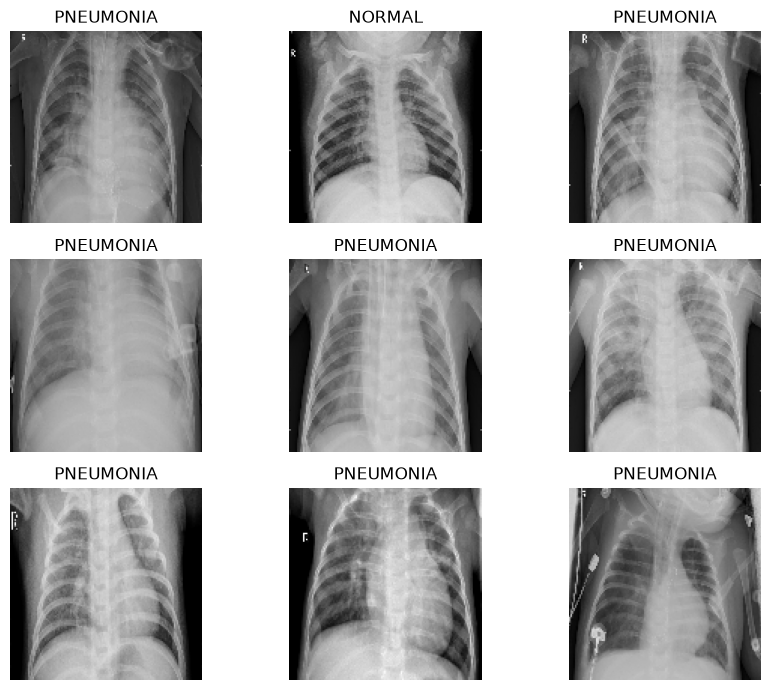

In [7]:
plt.figure(figsize=(9, 7))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray", vmin=0, vmax=255)
        plt.title(CLASS_NAMES[int(labels[i].numpy()[0])])
        plt.axis("off")
plt.tight_layout()
plt.show()

### Class weights

The dataset has far more PNEUMONIA than NORMAL images. Class weights make the loss treat both classes as equally important.

In [8]:
n_total = len(y_train)
class_weight = {
    0: float(n_total / (2.0 * (y_train == 0).sum())),
    1: float(n_total / (2.0 * (y_train == 1).sum())),
}
print("Class weights:", {k: round(v, 3) for k, v in class_weight.items()})

Class weights: {0: 1.939, 1: 0.674}


## 5. Model A – custom CNN

Four convolution blocks (Conv → BatchNorm → ReLU → MaxPool) with 16/32/64/128 filters, global average pooling, a regularised dense layer, dropout and a sigmoid output. Augmentation is applied only during training.

In [9]:
def make_augmentation(noise=True):
    aug_layers = [
        layers.RandomRotation(0.04),
        layers.RandomZoom(0.08),
        layers.RandomTranslation(0.04, 0.04),
        layers.RandomContrast(0.1),
    ]
    if noise:
        aug_layers.append(layers.GaussianNoise(0.05))
    return models.Sequential(aug_layers, name="data_augmentation")

def compile_model(m, lr):
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy",
                 tf.keras.metrics.AUC(name="auc"),
                 tf.keras.metrics.Precision(name="precision"),
                 tf.keras.metrics.Recall(name="recall")],
    )
    return m

def build_cnn():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = make_augmentation(noise=True)(x)
    for filters in (16, 32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu",
                     kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs, name="pneumonia_cnn")

cnn = compile_model(build_cnn(), lr=1e-3)
cnn.summary()

Model: "pneumonia_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 106,193 (414.82 KB)

 Trainable params: 105,713 (412.94 KB)

 Non-trainable params: 480 (1.88 KB)

## 6. Train Model A

Early stopping and checkpointing monitor **validation AUC**; the learning rate is halved when validation loss plateaus. The best weights are restored automatically.

In [10]:
def make_callbacks(tag):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6,
                                         restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
        tf.keras.callbacks.ModelCheckpoint(str(OUTPUT_DIR / f"best_{tag}.keras"),
                                           monitor="val_auc", mode="max", save_best_only=True),
    ]

history_cnn = cnn.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS, class_weight=class_weight,
    callbacks=make_callbacks("cnn"), verbose=2,
)

Epoch 1/30
131/131 - 56s - 427ms/step - accuracy: 0.8201 - auc: 0.9019 - loss: 0.4631 - precision: 0.9465 - recall: 0.8030 - val_accuracy: 0.7421 - val_auc: 0.5000 - val_loss: 2.3915 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/30
131/131 - 48s - 368ms/step - accuracy: 0.8839 - auc: 0.9488 - loss: 0.3433 - precision: 0.9672 - recall: 0.8731 - val_accuracy: 0.7421 - val_auc: 0.7876 - val_loss: 1.3866 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/30
131/131 - 48s - 363ms/step - accuracy: 0.9070 - auc: 0.9668 - loss: 0.2832 - precision: 0.9719 - recall: 0.9008 - val_accuracy: 0.7421 - val_auc: 0.8213 - val_loss: 1.3314 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/30
131/131 - 46s - 352ms/step - accuracy: 0.9137 - auc: 0.9736 - loss: 0.2561 - precision: 0.9764 - recall: 0.9057 - val_accuracy: 0.8682 - val_auc: 0.9707 - val_loss: 0.4210 - val_precision: 0.9908 - val_recall: 0.8301 - learning_rate:

## 7. Plot training curves (Model A)

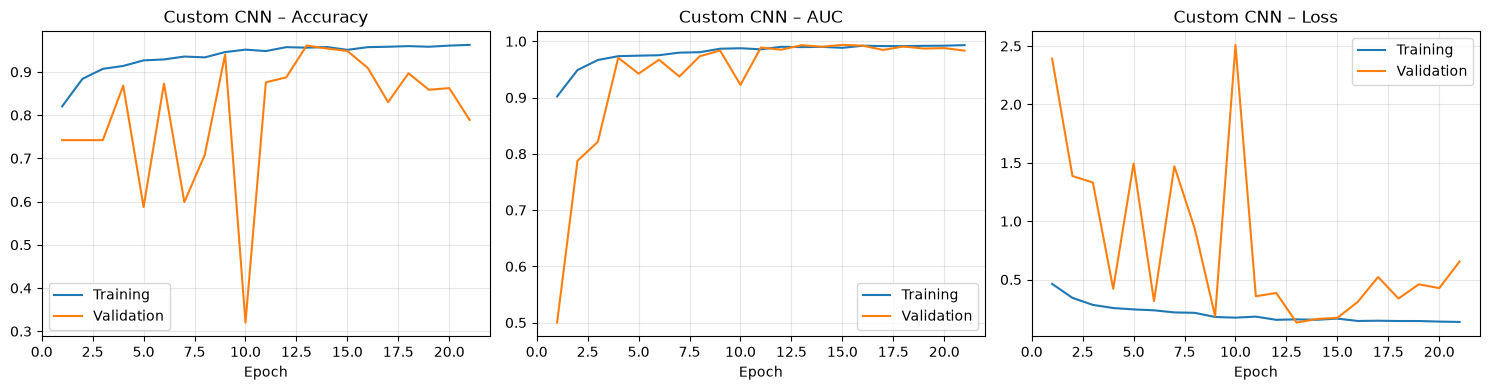

In [11]:
def plot_history(histories, title, fname):
    merged = {}
    for h in histories:
        for k, v in h.history.items():
            merged.setdefault(k, []).extend(v)
    ep = range(1, len(merged["loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (key, name) in zip(axes, [("accuracy", "Accuracy"), ("auc", "AUC"), ("loss", "Loss")]):
        ax.plot(ep, merged[key], label="Training")
        ax.plot(ep, merged["val_" + key], label="Validation")
        ax.set_title(f"{title} – {name}"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / fname, dpi=150)
    plt.show()

plot_history([history_cnn], "Custom CNN", "training_curves_cnn.png")

## 8. Model B (optional) – MobileNetV2 transfer learning

A MobileNetV2 backbone pre-trained on ImageNet is trained in two phases: (1) the new classification head only, then (2) fine-tuning the last layers with a low learning rate. Grayscale X-rays are replicated to 3 channels and scaled the way MobileNetV2 expects.

Set `RUN_TRANSFER_LEARNING = False` in the configuration cell to skip this section. It needs internet access once to download the ImageNet weights.

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 44s 5us/step
Phase 1: training the classification head
Epoch 1/10
131/131 - 73s - 560ms/step - accuracy: 0.8299 - auc: 0.9148 - loss: 0.3687 - precision: 0.9410 - recall: 0.8223 - val_accuracy: 0.8949 - val_auc: 0.9657 - val_loss: 0.2613 - val_precision: 0.9757 - val_recall: 0.8803 - learning_rate: 0.0010
Epoch 2/10
131/131 - 47s - 361ms/step - accuracy: 0.8984 - auc: 0.9662 - loss: 0.2327 - precision: 0.9702 - recall: 0.8905 - val_accuracy: 0.8988 - val_auc: 0.9758 - val_loss: 0.2445 - val_precision: 0.9827 - val_recall: 0.8790 - learning_rate: 0.0010
Epoch 3/10
131/131 - 49s - 374ms/step - accuracy: 0.9137 - auc: 0.9747 - loss: 0.2006 - precision: 0.9771 - recall: 0.9050 - val_accuracy: 0.9045 - val_auc: 0.9785 - val_loss: 0.2268 - val_precision: 0.9829 - val_recall: 0.8867 - learning_rate: 0.0010
Epoch 4/10
131/131 - 46s - 349ms/step - accuracy: 0.9178 - auc: 0.9778 - loss: 0.1894 - precision: 0.9769 - recall: 0.9108 - val_accuracy: 0.9064 - val_

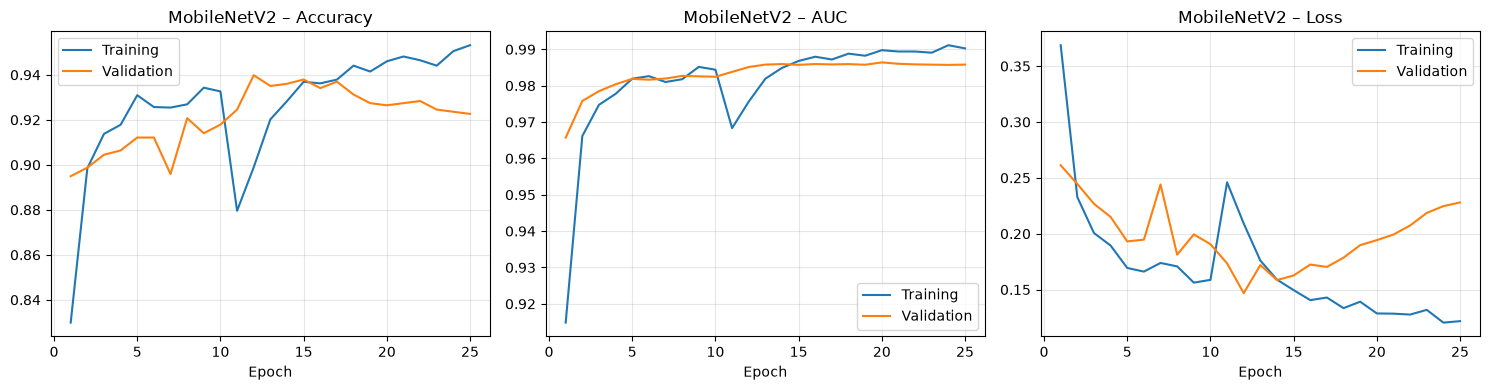

In [12]:
def build_transfer(weights="imagenet"):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=weights)
    base.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = make_augmentation(noise=False)(inputs)
    x = layers.Concatenate()([x, x, x])                    # grayscale -> 3 channels
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)      # MobileNetV2 expects [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs, name="pneumonia_mobilenetv2"), base

if RUN_TRANSFER_LEARNING:
    tl_model, tl_base = build_transfer(TL_WEIGHTS)
    compile_model(tl_model, lr=1e-3)

    print("Phase 1: training the classification head")
    h1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=min(10, EPOCHS),
                      class_weight=class_weight, callbacks=make_callbacks("mobilenetv2_head"), verbose=2)

    print("\nPhase 2: fine-tuning the last 30 layers")
    tl_base.trainable = True
    for layer in tl_base.layers[:-30]:
        layer.trainable = False
    compile_model(tl_model, lr=1e-5)
    h2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=min(15, EPOCHS),
                      class_weight=class_weight, callbacks=make_callbacks("mobilenetv2_ft"), verbose=2)

    plot_history([h1, h2], "MobileNetV2", "training_curves_mobilenetv2.png")
else:
    print("Transfer learning skipped.")

## 9. Evaluate on the held-out test set

* The decision threshold is chosen **on the validation set** (Youden's J: maximises sensitivity + specificity − 1), never on the test set.
* The test set is then reported at both the default threshold (0.5) and the tuned threshold.
* For a medical task, look at **PNEUMONIA recall (sensitivity)** – missed pneumonia cases are false negatives – and **NORMAL recall (specificity)** together, not accuracy alone.


===== Custom CNN | threshold = 0.500 =====
              precision    recall  f1-score   support

      NORMAL     0.9070    0.6667    0.7685       234
   PNEUMONIA     0.8274    0.9590    0.8884       390

    accuracy                         0.8494       624
   macro avg     0.8672    0.8128    0.8284       624
weighted avg     0.8573    0.8494    0.8434       624



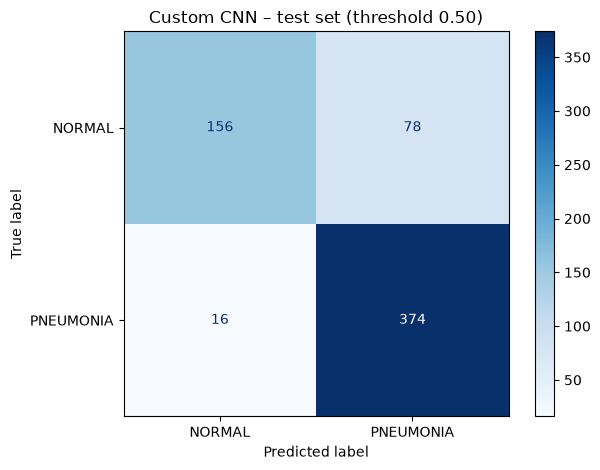


===== Custom CNN | threshold = 0.427 =====
              precision    recall  f1-score   support

      NORMAL     0.9141    0.6368    0.7506       234
   PNEUMONIA     0.8156    0.9641    0.8837       390

    accuracy                         0.8413       624
   macro avg     0.8649    0.8004    0.8171       624
weighted avg     0.8526    0.8413    0.8338       624



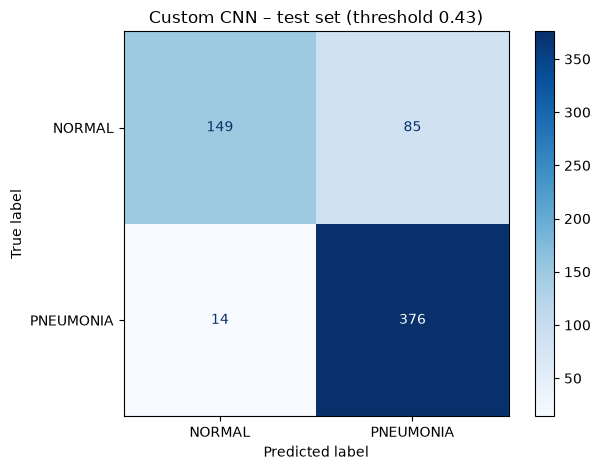


===== MobileNetV2 | threshold = 0.500 =====
              precision    recall  f1-score   support

      NORMAL     0.9095    0.7735    0.8360       234
   PNEUMONIA     0.8753    0.9538    0.9129       390

    accuracy                         0.8862       624
   macro avg     0.8924    0.8637    0.8745       624
weighted avg     0.8881    0.8862    0.8841       624



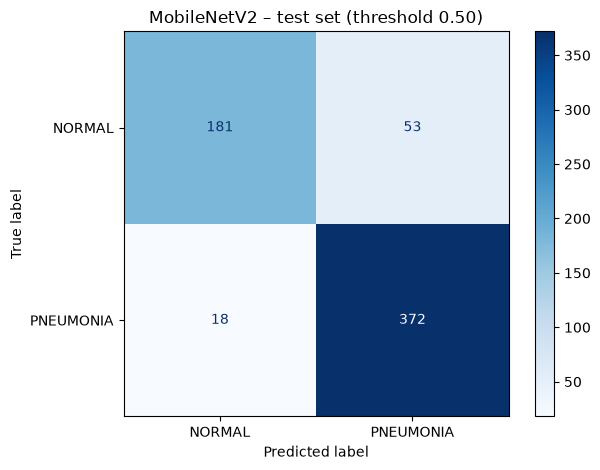


===== MobileNetV2 | threshold = 0.099 =====
              precision    recall  f1-score   support

      NORMAL     0.9710    0.5726    0.7204       234
   PNEUMONIA     0.7942    0.9897    0.8813       390

    accuracy                         0.8333       624
   macro avg     0.8826    0.7812    0.8009       624
weighted avg     0.8605    0.8333    0.8210       624



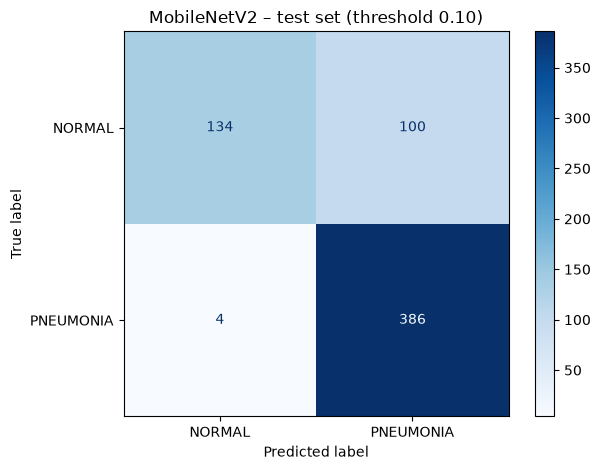

In [13]:
def predict_probs(m, ds):
    return m.predict(ds, verbose=0).ravel()

def tune_threshold(y_true, probs):
    fpr, tpr, thr = roc_curve(y_true, probs)
    j = tpr - fpr
    return float(np.clip(thr[np.argmax(j)], 0.01, 0.99))

def evaluate_model(name, y_true, probs, threshold, show=True):
    pred = (probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    res = {
        "model": name, "threshold": round(threshold, 3),
        "accuracy": (tp + tn) / cm.sum(),
        "pneumonia_precision": tp / max(tp + fp, 1),
        "pneumonia_recall": tp / max(tp + fn, 1),
        "normal_recall": tn / max(tn + fp, 1),
        "pneumonia_f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "roc_auc": roc_auc_score(y_true, probs),
        "false_negatives": int(fn), "false_positives": int(fp),
        "confusion_matrix": cm.tolist(),
    }
    if show:
        print(f"\n===== {name} | threshold = {threshold:.3f} =====")
        print(classification_report(y_true, pred, labels=[0, 1], target_names=CLASS_NAMES,
                                    digits=4, zero_division=0))
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", values_format="d")
        plt.title(f"{name} – test set (threshold {threshold:.2f})")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"confusion_{name.replace(' ', '_')}_{threshold:.2f}.png", dpi=150)
        plt.show()
    return res

trained = {"Custom CNN": cnn}
if RUN_TRANSFER_LEARNING:
    trained["MobileNetV2"] = tl_model

all_results, probs_test, probs_val, thresholds = [], {}, {}, {}
for name, m in trained.items():
    probs_val[name]  = predict_probs(m, val_ds)
    probs_test[name] = predict_probs(m, test_ds)
    thresholds[name] = tune_threshold(y_val, probs_val[name])
    all_results.append(evaluate_model(name, y_test, probs_test[name], 0.5))
    all_results.append(evaluate_model(name, y_test, probs_test[name], thresholds[name]))
    all_results[-2]["threshold_type"] = "default 0.5"
    all_results[-1]["threshold_type"] = "tuned on validation"

### ROC curves (test set)

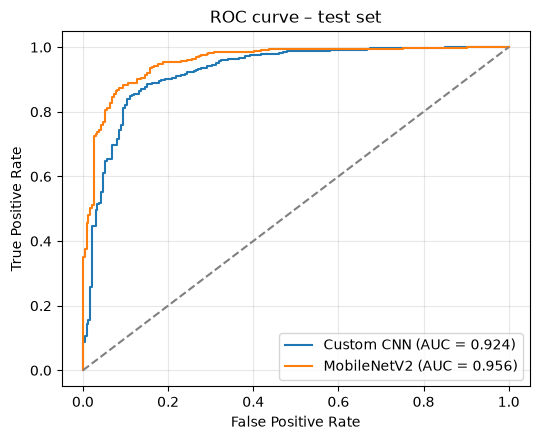

In [14]:
plt.figure(figsize=(5.5, 4.5))
for name in trained:
    fpr, tpr, _ = roc_curve(y_test, probs_test[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs_test[name]):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve – test set"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=150)
plt.show()

## 10. Model comparison and selection

The final model is chosen by **validation** AUC so the test set is not used for model selection.

In [15]:
table = pd.DataFrame(all_results)[[
    "model", "threshold_type", "threshold", "accuracy", "pneumonia_precision",
    "pneumonia_recall", "normal_recall", "pneumonia_f1", "roc_auc",
    "false_negatives", "false_positives"]]
display_table = table.copy()
for c in ["accuracy", "pneumonia_precision", "pneumonia_recall", "normal_recall", "pneumonia_f1", "roc_auc"]:
    display_table[c] = display_table[c].round(4)
print(display_table.to_string(index=False))

val_auc = {n: roc_auc_score(y_val, p) for n, p in probs_val.items()}
print("\nValidation AUC:", {k: round(v, 4) for k, v in val_auc.items()})
final_name = max(val_auc, key=val_auc.get)
final_model = trained[final_name]
final_threshold = thresholds[final_name]
print(f"Selected final model (by validation AUC): {final_name} | threshold = {final_threshold:.3f}")

      model      threshold_type  threshold  accuracy  pneumonia_precision  pneumonia_recall  normal_recall  pneumonia_f1  roc_auc  false_negatives  false_positives
 Custom CNN         default 0.5      0.500    0.8494               0.8274            0.9590         0.6667        0.8884   0.9244               16               78
 Custom CNN tuned on validation      0.427    0.8413               0.8156            0.9641         0.6368        0.8837   0.9244               14               85
MobileNetV2         default 0.5      0.500    0.8862               0.8753            0.9538         0.7735        0.9129   0.9561               18               53
MobileNetV2 tuned on validation      0.099    0.8333               0.7942            0.9897         0.5726        0.8813   0.9561                4              100

Validation AUC: {'Custom CNN': 0.9939, 'MobileNetV2': 0.9877}
Selected final model (by validation AUC): Custom CNN | threshold = 0.427


## 11. Save the model and the actual results

In [16]:
final_model.save(OUTPUT_DIR / "pneumonia_final_model.keras")

results = {
    "final_model": final_name,
    "final_threshold": final_threshold,
    "class_weight": {str(k): float(v) for k, v in class_weight.items()},
    "data_split": summary.to_dict(orient="records"),
    "validation_auc": {k: float(v) for k, v in val_auc.items()},
    "test_results": all_results,
    "parameter_counts": {n: int(m.count_params()) for n, m in trained.items()},
}
with open(OUTPUT_DIR / "results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
display_table.to_csv(OUTPUT_DIR / "results_table.csv", index=False)

print("Saved model:", (OUTPUT_DIR / "pneumonia_final_model.keras").resolve())
print("Saved plots/results in:", OUTPUT_DIR.resolve())

Saved model: D:\Desktop\DL laib mid\cnn_outputs\pneumonia_final_model.keras
Saved plots/results in: D:\Desktop\DL laib mid\cnn_outputs


## 12. Predict a new X-ray image

Set `IMAGE_PATH` to a JPG/JPEG/PNG file. If you leave it empty, a file-picker window opens (works on a normal desktop VS Code session). The score is the model's output for the PNEUMONIA class; it is not a calibrated medical probability.

In [ ]:
IMAGE_PATH = ""      # e.g. r"C:\Users\Admin\Downloads\chest_xray\test\PNEUMONIA\person1_virus_6.jpeg"

if not IMAGE_PATH:
    try:
        from tkinter import Tk, filedialog
        root = Tk(); root.withdraw()
        IMAGE_PATH = filedialog.askopenfilename(
            title="Select a chest X-ray image",
            filetypes=[("Image files", "*.jpg *.jpeg *.png")])
        root.destroy()
    except Exception as e:
        print("File picker unavailable, set IMAGE_PATH manually:", e)

if IMAGE_PATH:
    pil_img = Image.open(IMAGE_PATH).convert("L")
    batch = prepare_image(np.asarray(pil_img))[None, ...]
    score = float(final_model.predict(batch, verbose=0)[0, 0])
    label = "PNEUMONIA" if score >= final_threshold else "NORMAL"

    plt.imshow(pil_img, cmap="gray"); plt.axis("off")
    plt.title(f"Prediction: {label}"); plt.show()
    print("Predicted class:", label)
    print(f"Pneumonia model score: {score:.2%}  (decision threshold {final_threshold:.2f})")
    print("Educational demonstration only – not a medical diagnosis.")
else:
    print("No image selected.")

## 13. Optional: Gradio web interface

Run after training. It starts a small local web app for uploading an X-ray and getting a prediction.

In [1]:
import gradio as gr

def predict_xray(input_image):
    if input_image is None:
        return {"NORMAL": 0.0, "PNEUMONIA": 0.0}, "Please upload an X-ray image."
    arr = prepare_image(np.asarray(input_image.convert("L")))[None, ...]
    score = float(final_model.predict(arr, verbose=0)[0, 0])
    label = "PNEUMONIA" if score >= final_threshold else "NORMAL"
    note = f"Prediction: **{label}**\n\nEducational demonstration only – not a medical diagnosis."
    return {"NORMAL": 1.0 - score, "PNEUMONIA": score}, note

demo = gr.Interface(
    fn=predict_xray,
    inputs=gr.Image(type="pil", label="Upload chest X-ray"),
    outputs=[gr.Label(num_top_classes=2, label="Model scores"), gr.Markdown()],
    title="Pneumonia Detection from Chest X-rays (CNN)",
    description="Educational image-classification demonstration.",
)
demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Traceback (most recent call last):
  File "c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\gradio\queueing.py", line 870, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<6 lines>...
    )
    ^
  File "c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\gradio\route_utils.py", line 418, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\gradio\blocks.py", line 2698, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<9 lines>...
    )
    ^
  File "c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\gradio\blocks.py", line 1963, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
      

Created dataset file at: .gradio\flagged\dataset1.csv


## 14. Conclusion

This notebook trains a custom CNN (and optionally a MobileNetV2 transfer-learning model) to classify chest X-rays as NORMAL or PNEUMONIA. Improvements over the original version: patient-grouped train/validation split, class weighting, full-resolution input, BatchNorm, realistic augmentation, validation-based threshold tuning, and an unbiased model selection step.

**Use the table printed in Section 10 for your report** – it is generated from your own run, so the numbers always match what you actually trained. Report at least: test accuracy, PNEUMONIA precision / recall / F1, NORMAL recall, ROC-AUC and the confusion matrix.

**Things worth discussing in a report**
* The Kaggle test set is small (624 images) and is known to be distribution-shifted from the training set, so test accuracy is typically lower than validation accuracy and NORMAL recall is the weakest metric. This is expected and should be reported honestly.
* A high ROC-AUC with a modest accuracy at threshold 0.5 usually means the threshold, not the ranking ability, is the problem; that is why the tuned threshold is shown too.
* Patient-level IDs are inferred from file names; this is a best-effort guard against leakage, not a guarantee.

**Limitation:** this model is for educational purposes only. It is not clinically validated and must not be used for diagnosis or treatment decisions.